## SST dataset downloader

In [19]:
import os
import numpy as np
import xarray as xr
import urllib.request
import urllib.error
import time
import http.client
import socket
import re
import glob


## 0- General parameters
DATA_DIR = "datasets/Data_sst"
DATA_DIR_CLEAN = "datasets/Data_sst_clean"
FINAL_DATA_DIR = "datasets"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(DATA_DIR_CLEAN, exist_ok=True)
BASE_URL = "https://downloads.psl.noaa.gov/Datasets/noaa.oisst.v2.highres/"

## 1- Download parameters
START_YEAR = 2025
END_YEAR = 2025
MASK_FILE = "lsmask.oisst.nc"
YEAR_FILE_TEMPLATE = "sst.day.mean.{year}.nc"
YEAR_FILES = [f"sst.day.mean.{y}.nc" for y in range(START_YEAR, END_YEAR + 1)]

## 2- Resize parameters
DOWNSAMPLE_FACTOR = 4       #square 4*4 pixels -> 1 pixel

## 1- Download

In [20]:
def _remote_size(url, timeout=20):
    try:
        headers = {"User-Agent": "Mozilla/5.0 (compatible; sst-downloader/1.0)"}
        request = urllib.request.Request(url, method="HEAD", headers=headers)
        with urllib.request.urlopen(request, timeout=timeout) as response:
            size = response.headers.get("Content-Length")
        return int(size) if size is not None else None
    except Exception as exc:
        print(f"  could not determine remote size via HEAD ({exc}); will size from GET instead.")
        return None

def _download(filename, max_retries=200, timeout=20):
    path = os.path.join(DATA_DIR, filename)
    url = BASE_URL + filename
    headers = {"User-Agent": "Mozilla/5.0 (compatible; sst-downloader/1.0)"}

    expected_size = _remote_size(url)
    if os.path.exists(path) and expected_size is not None and os.path.getsize(path) == expected_size:
        print(f"{filename} already present, skipping download.")
        return path

    # if exists already in Data_cleaned, skip download
    year_match = re.search(r"(\d{4})", filename)
    path_cleaned = os.path.join(DATA_DIR_CLEAN, f"sst_{year_match.group(1)}.npy") if year_match else None
    if path_cleaned and os.path.exists(path_cleaned):
        print(f"{filename} already processed and present in cleaned data, skipping download.")
        return path_cleaned

    tmp_path = os.path.join(DATA_DIR, f".{filename}.part")
    attempt = 0

    while True:
        attempt += 1
        resume_from = os.path.getsize(tmp_path) if os.path.exists(tmp_path) else 0

        if expected_size is not None and resume_from >= expected_size:
            break  # done

        if attempt > max_retries:
            raise IOError(
                f"Gave up after {max_retries} attempts: "
                f"{resume_from} out of {expected_size} bytes for {filename}"
            )

        req_headers = dict(headers)
        mode = "wb"
        if resume_from > 0:
            req_headers["Range"] = f"bytes={resume_from}-"
            mode = "ab"

        pct = (resume_from / expected_size * 100) if expected_size else 0
        print(f"[attempt {attempt}] {filename}: {resume_from}/{expected_size} bytes ({pct:.1f}%)")

        try:
            request = urllib.request.Request(url, headers=req_headers)
            with urllib.request.urlopen(request, timeout=timeout) as response:
                if resume_from > 0 and response.status == 200:
                    # server ignored Range, restart from scratch
                    resume_from = 0
                    mode = "wb"

                with open(tmp_path, mode) as target:
                    while True:
                        try:
                            chunk = response.read(1024 * 256)
                        except (socket.timeout, http.client.IncompleteRead) as e:
                            raise IOError(f"stream interrupted: {e}")
                        if not chunk:
                            break
                        target.write(chunk)

            # Response body fully consumed without error.
            if expected_size is None:
                # We didn't know the size upfront (HEAD failed); trust that a
                # clean read-to-EOF means the transfer completed successfully.
                expected_size = os.path.getsize(tmp_path)
            break

        except (urllib.error.URLError, socket.timeout, http.client.IncompleteRead,
                ConnectionResetError, TimeoutError, OSError) as exc:
            wait = min(2 + attempt // 5, 15)
            print(f"  interrupted: {exc}. Resuming in {wait}s...")
            time.sleep(wait)
            continue

    got = os.path.getsize(tmp_path)
    if expected_size is not None and got != expected_size:
        raise IOError(f"retrieval incomplete after loop: got {got} out of {expected_size} bytes")

    os.replace(tmp_path, path)
    print(f"{filename} download complete.")
    return path

_download(MASK_FILE)  
for fname in YEAR_FILES:
    F = _download(fname)
    del F

[attempt 1] lsmask.oisst.nc: 0/4157776 bytes (0.0%)
lsmask.oisst.nc download complete.
[attempt 1] sst.day.mean.2025.nc: 0/474901771 bytes (0.0%)
sst.day.mean.2025.nc download complete.


## 2 - Resize 

raw shape: (365, 720, 1440)
shape after averaging: (365, 180, 360)


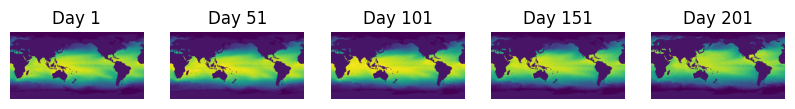

Removed original file: datasets/Data_sst/sst.day.mean.2025.nc
Saved the resized data: datasets/Data_sst_clean/sst_2025.npy | shape=(365, 64800)


In [27]:
def _load_and_modify_year_matrix(year_file, mask_file, verbose=False):

    # data extraction
    year_path = os.path.join(DATA_DIR, year_file)
    mask_path = os.path.join(DATA_DIR, mask_file)
    ds_year = xr.open_dataset(year_path)
    ds_mask = xr.open_dataset(mask_path)
    data = ds_year["sst"].values         # (time, lat, lon)
    mask = ds_mask["lsmask"].values      # (time, lat, lon) or (lat, lon)

    if verbose:
        print(f"raw shape: {data.shape}")
    ds_year.close()
    ds_mask.close()

    # The mask file includes a singleton leading time dimension; squeeze it to 2D.
    mask = np.squeeze(mask)
    if mask.ndim != 2:
        raise ValueError(f"Expected a 2D mask after squeezing, got shape {mask.shape}")
    if mask.shape != data.shape[1:]:
        raise ValueError(
            f"Mask spatial shape {mask.shape} does not match SST spatial shape {data.shape[1:]}"
        )

    # Subsample the data by averaging 4x4 blocks to reduce resolution
    data = data.reshape(
        data.shape[0],
        data.shape[1] // DOWNSAMPLE_FACTOR,
        DOWNSAMPLE_FACTOR,
        data.shape[2] // DOWNSAMPLE_FACTOR,
        DOWNSAMPLE_FACTOR,
    ).mean(axis=(2, 4))
    mask = mask.reshape(
        mask.shape[0] // DOWNSAMPLE_FACTOR,
        DOWNSAMPLE_FACTOR,
        mask.shape[1] // DOWNSAMPLE_FACTOR,
        DOWNSAMPLE_FACTOR,
    ).mean(axis=(1, 3)) > 0.5

    # Handle NaN values and flip latitude axis for visualization consistency
    data = np.nan_to_num(data, nan=0.0)
    data[:, ~mask] = 0.0            # Apply land-sea mask: set land pixels to 0
    data = np.flip(data, axis=1)    # Flip latitude axis for visualization consistency

    if verbose:
        print(f"shape after averaging: {data.shape}")
        import matplotlib.pyplot as plt
        plt.figure(figsize=(10, 5))
        for i in range(5):
            plt.subplot(1, 5, i + 1)
            plt.imshow(data[i*50], cmap='viridis')
            plt.title(f"Day {i*50+1}")
            plt.axis('off')
        plt.show()

    data = data.reshape(data.shape[0], -1)  # (time, lat*lon)
    del ds_year, ds_mask
    return data

def _resize_all_years():

    for year in range(START_YEAR, END_YEAR + 1):
        year_file = YEAR_FILE_TEMPLATE.format(year=year)
        year_path = os.path.join(DATA_DIR, year_file)

        if not os.path.exists(year_path):
            print(f"Skipping {year} already processed -> {year_path}")
            continue

        data = _load_and_modify_year_matrix(year_file, MASK_FILE, verbose=True)
        # remove the original file to save space
        os.remove(year_path)
        print(f"Removed original file: {year_path}")
        output_path = os.path.join(DATA_DIR_CLEAN, f"sst_{year}.npy")
        np.save(output_path, data)
        print(f"Saved the resized data: {output_path} | shape={data.shape}")

_resize_all_years()

## 3 - Unify

In [32]:
def _unify():
    files = sorted(glob.glob(os.path.join(DATA_DIR_CLEAN, "*.npy")))

    arrays = []
    first_shape = None

    for f in files:
        arr = np.load(f)
        if arr.ndim != 2:
            raise ValueError(f"Expected 2D (time, data) array in {f}, got shape {arr.shape}")

        if first_shape is None:
            first_shape = arr.shape
        elif arr.shape[1] != first_shape[1]:
            raise ValueError(
                f"Feature dimension mismatch in {f}: expected {first_shape[1]}, got {arr.shape[1]}"
            )

        arrays.append(arr)
        print(f"Loaded {os.path.basename(f)} with shape {arr.shape}, total time steps so far: {sum(a.shape[0] for a in arrays)}")

    # Stack all years along time axis: (sum_time, data)
    data = np.concatenate(arrays, axis=0)
    print(f"Final stacked data shape: {data.shape}")
    # save the stacked data to a new .npy file in the  final data directory
    output_file = os.path.join(FINAL_DATA_DIR, "sst_all.npy")
    np.save(output_file, data)

_unify()

Loaded sst_2010.npy with shape (365, 64800), total time steps so far: 365
Loaded sst_2011.npy with shape (365, 64800), total time steps so far: 730
Loaded sst_2012.npy with shape (366, 64800), total time steps so far: 1096
Loaded sst_2013.npy with shape (365, 64800), total time steps so far: 1461
Loaded sst_2014.npy with shape (365, 64800), total time steps so far: 1826
Loaded sst_2015.npy with shape (365, 64800), total time steps so far: 2191
Loaded sst_2016.npy with shape (366, 64800), total time steps so far: 2557
Loaded sst_2017.npy with shape (365, 64800), total time steps so far: 2922
Loaded sst_2018.npy with shape (365, 64800), total time steps so far: 3287
Loaded sst_2019.npy with shape (365, 64800), total time steps so far: 3652
Loaded sst_2020.npy with shape (366, 64800), total time steps so far: 4018
Loaded sst_2021.npy with shape (365, 64800), total time steps so far: 4383
Loaded sst_2022.npy with shape (365, 64800), total time steps so far: 4748
Loaded sst_2023.npy with sh

## 4 - Remove the data directories

In [ ]:
# remove the foler Data_sst and Data_sst_clean to save space
import shutil
#shutil.rmtree(DATA_DIR)
#shutil.rmtree(DATA_DIR_CLEAN)